In [1]:
import numpy as np
import pandas as pd

In [50]:
df = pd.read_csv("nlp_field_observation_augmented.csv")
print(df.head())

                                         observation  score
0                             Dense and dry terrain.      4
1  The soil is acceptable firmness and partially ...      3
2  Foundations would sit on collapsing and no bea...      1
3            Observation: very hard and undisturbed.      5
4                                    Sinking ground.      1


In [51]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)


In [52]:
df.head()

,observation,score
0,Ground appears stable enough and stable enough.,3
1,Excavation reveals extremely dense layers.,5
2,Site consists of moderate stiffness material.,3
3,Excavation reveals fluid-like layers.,1
4,Foundations would sit on partially settled earth.,3


In [53]:
# Splitting input and output into X and y
X = df["observation"]  # text input
y = df["score"]        # target score (1–5)


# Doing train test split
from sklearn.model_selection import train_test_split

# X = text, y = scores
X_train, X_test, y_train, y_test = train_test_split(
    df["observation"], df["score"], 
    test_size=0.2,  # 20% for testing
    random_state=42
)


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1,2), # bigram
    max_features=1000   # limit features for Random Forest
)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)


In [55]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    max_depth= 10,
    min_samples_leaf= 1, 
    min_samples_split= 2, 
    n_estimators= 300
)
rf_model.fit(X_train_tfidf, y_train)
y_pred = rf_model.predict(X_test_tfidf)


In [57]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [200, 300, 400],
    'max_depth': [10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5)
grid.fit(X_train_tfidf, y_train)

best_rf = grid.best_estimator_
print("Best params:", grid.best_params_)


Best params: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 400}


Accuracy: 86.11 %

Classification Report:
              precision    recall  f1-score   support

           1       1.00      0.27      0.43        33
           2       0.85      1.00      0.92        46
           3       0.81      0.99      0.89        77
           4       0.91      0.91      0.91        35
           5       0.96      0.92      0.94        25

    accuracy                           0.86       216
   macro avg       0.91      0.82      0.82       216
weighted avg       0.88      0.86      0.84       216



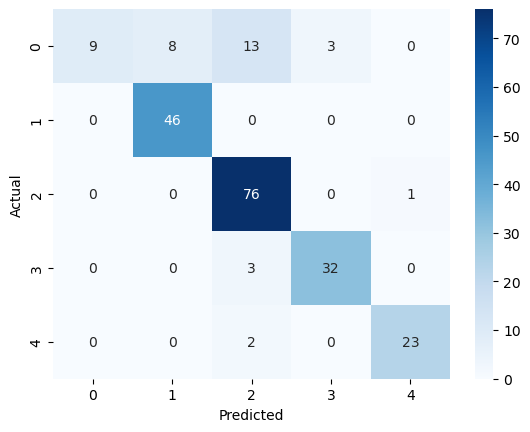

In [56]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Simple accuracy
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", round(acc*100, 2), "%")

# Detailed report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Optional: Confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [58]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load dataset
df = pd.read_csv("nlp_field_observation.csv")

# Split features and target
X_train, X_test, y_train, y_test = train_test_split(
    df["observation"], df["score"], test_size=0.2, random_state=42
)

# Adjust target for XGBoost (0-indexed classes)
y_train = y_train - 1
y_test = y_test - 1

# Convert text to TF-IDF features
vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1,3), max_features=1000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.1,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42
)

# Train the model
xgb_model.fit(X_train_tfidf, y_train)

# Predict
y_pred = xgb_model.predict(X_test_tfidf)

# Convert back to original score (1-5)
y_pred_original = y_pred + 1
y_test_original = y_test + 1

# Evaluate
accuracy = accuracy_score(y_test_original, y_pred_original)
print("XGBoost Accuracy:", round(accuracy*100, 2), "%")
print("\nClassification Report:\n", classification_report(y_test_original, y_pred_original))


c:\Users\User\anaconda3\Lib\site-packages\xgboost\training.py:199: UserWarning: [09:22:29] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Accuracy: 56.25 %

Classification Report:
               precision    recall  f1-score   support

           1       0.67      0.40      0.50         5
           2       0.43      0.75      0.55         4
           3       1.00      0.50      0.67         6
           4       0.50      1.00      0.67         1
           5       0.00      0.00      0.00         0

    accuracy                           0.56        16
   macro avg       0.52      0.53      0.48        16
weighted avg       0.72      0.56      0.58        16



c:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
